# Task: Edge Detection Filters 

**Goal:** apply every filter we covered to **your own picture**, compare the results, and explain what you see.

**Rules**
- Use your own image (a photo with clear objects and some texture works best, not a blank wall).
- Write the code yourself where you see `# TODO`. Hints are given, not solutions.
- Every plot needs a title. Use `plt.figure(figsize=...)` so images are readable.

**Submit:** this notebook with outputs visible + your answers.

## Part 0: Setup & Load Your Image

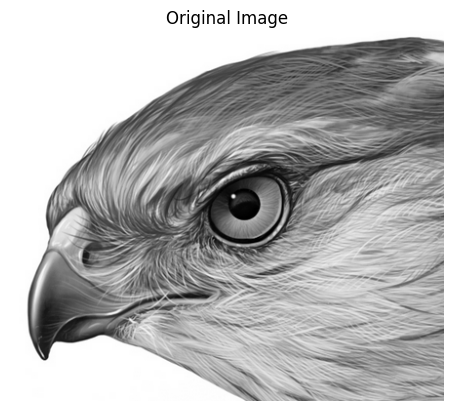

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

path = r"D:\Documents\term\Skyxpert\cv\SkyXperts-Vision-Course-master\Session2\images\hawk.png"

# TODO: load the image in grayscale and display it
# Hint: cv2.imread(..., cv2.IMREAD_GRAYSCALE), then plt.imshow(..., cmap="gray")
img = cv2.imread(path, 0)  # Use grayscale for filtering
plt.imshow(img, cmap='gray'); plt.axis('off'); plt.title('Original Image'); 
plt.show()

**Question 0:** What is the size (height × width) of your image? Why do we convert to grayscale before edge detection?

*Your answer:* 

## Part 1: Gradients (Sobel)

Compute the horizontal and vertical derivatives, then the magnitude and orientation.

Formulas: `mag = sqrt(gx² + gy²)` and `θ = arctan2(gy, gx)`

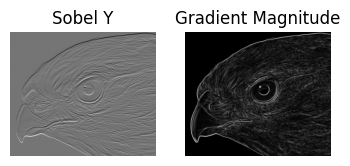

In [3]:
# TODO: compute grad_x and grad_y using cv2.Sobel with cv2.CV_64F and ksize=3
grad_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
grad_y = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

# TODO: compute magnitude and orientation (in degrees)
magnitude = np.sqrt(grad_x**2 + grad_y**2)
orientation = np.degrees(np.arctan2(grad_y, grad_x))

# TODO: show grad_x, grad_y and magnitude side by side (1 row, 3 columns)
plt.subplot(1, 3, 2)
plt.imshow(grad_y, cmap='gray')
plt.title("Sobel Y")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(magnitude, cmap='gray')
plt.title("Gradient Magnitude")
plt.axis('off')

plt.show()

**Question 1a:** Which gradient (X or Y) highlights vertical lines in your image? Point out one object in your picture that proves it.

**Question 1b:** Why do we use `cv2.CV_64F` instead of the default `uint8` here? (Hint: what happens to negative values?)

*Your answers:* 

## Part 2: Laplacian

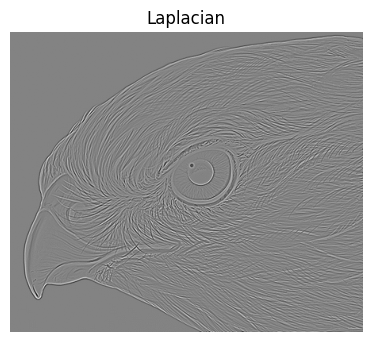

In [5]:
# TODO: apply the Laplacian and show it next to the original
laplacian = cv2.Laplacian(img, cv2.CV_64F)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 2)
plt.imshow(laplacian, cmap='gray')
plt.title("Laplacian")
plt.axis('off')

plt.show()

**Question 2:** What is the difference between what the Laplacian gives you and what the Sobel gradients gave you? Does it tell you the edge direction?

*Your answer:* 

## Part 3: Canny

Try **three different threshold pairs** (low, high), for example a low pair, a medium pair, and a high pair.

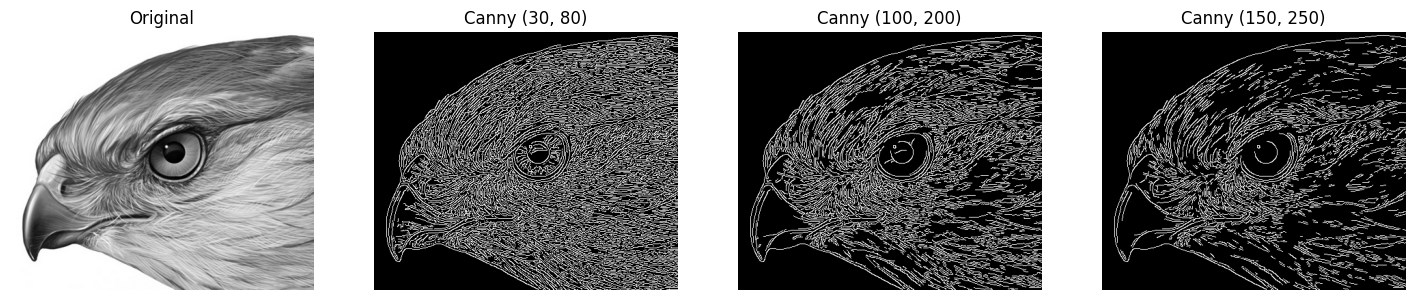

In [6]:
# TODO: run cv2.Canny with 3 different (low, high) threshold pairs
canny_low = cv2.Canny(img, 30, 80)
canny_medium = cv2.Canny(img, 100, 200)
canny_high = cv2.Canny(img, 150, 250)

# TODO: show the original + the 3 results in one figure (1 row, 4 columns)
plt.figure(figsize=(18, 5))

images = [
    (img, "Original"),
    (canny_low, "Canny (30, 80)"),
    (canny_medium, "Canny (100, 200)"),
    (canny_high, "Canny (150, 250)")
]

# Put the thresholds in each subplot title
for i, (image, title) in enumerate(images):
    plt.subplot(1, 4, i + 1)
    plt.imshow(image, cmap='gray')
    plt.title(title)
    plt.axis('off')

plt.show()


**Question 3a:** What happens to the edges as you increase the thresholds?

**Question 3b:** List the 5 steps of the Canny pipeline in order.

*Your answers:* 

## Part 4: Roberts & Prewitt (Your Own Kernels)

Define the kernels yourself as NumPy arrays and apply them with `cv2.filter2D`.

- Roberts: 2×2 kernels
- Prewitt: 3×3 kernels (X and Y)

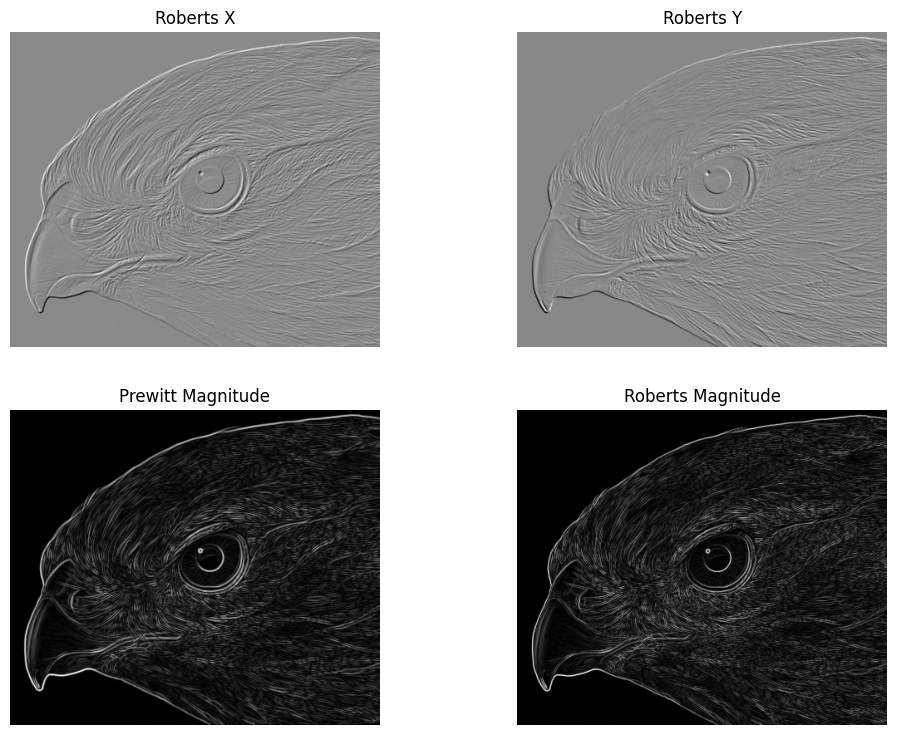

In [7]:
# TODO: define roberts_x, roberts_y, prewitt_x, prewitt_y
roberts_x = np.array([
    [1, 0],
    [0, -1]
], dtype=np.float32)

roberts_y = np.array([
    [0, 1],
    [-1, 0]
], dtype=np.float32)

# Prewitt kernels
prewitt_x = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float32)

prewitt_y = np.array([
    [-1, -1, -1],
    [0, 0, 0],
    [1, 1, 1]
], dtype=np.float32)

# TODO: apply each with cv2.filter2D(img, -1, kernel)
roberts_result_x = cv2.filter2D(img, cv2.CV_64F, roberts_x)
roberts_result_y = cv2.filter2D(img, cv2.CV_64F, roberts_y)

prewitt_result_x = cv2.filter2D(img, cv2.CV_64F, prewitt_x)
prewitt_result_y = cv2.filter2D(img, cv2.CV_64F, prewitt_y)

# Calculate magnitudes for visualization
roberts_magnitude = cv2.magnitude(
    roberts_result_x, roberts_result_y
)

prewitt_magnitude = cv2.magnitude(
    prewitt_result_x, prewitt_result_y
)

# TODO: show the 4 results in a 2x2 grid
plt.figure(figsize=(12, 9))

results = [
    (roberts_result_x, "Roberts X"),
    (roberts_result_y, "Roberts Y"),
    (prewitt_magnitude, "Prewitt Magnitude"),
    (roberts_magnitude, "Roberts Magnitude")
]

for i, (image, title) in enumerate(results):
    plt.subplot(2, 2, i + 1)
    plt.imshow(image, cmap='gray')
    plt.title(title)
    plt.axis('off')

plt.show()

**Question 4:** Which one (Roberts or Prewitt) looks noisier on your image? Why do you think that is (think about kernel size)?

*Your answer:* 

## Part 5: Sobel 3×3 vs 5×5

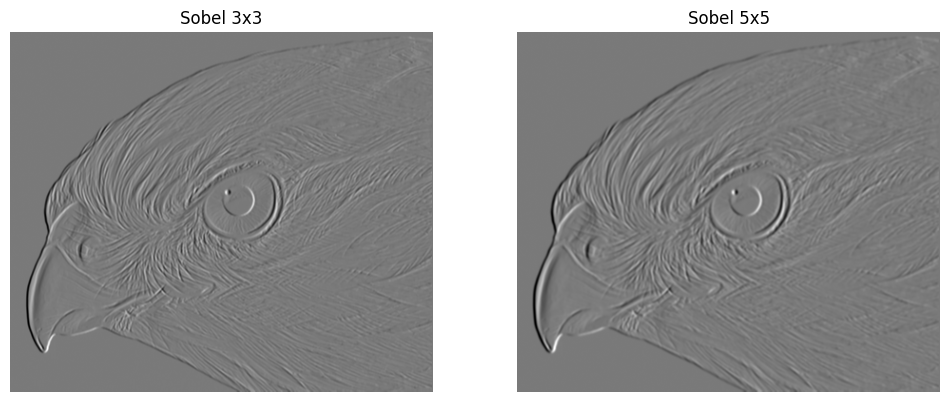

In [8]:
# TODO: apply Sobel in the X direction with ksize=3 and ksize=5, show side by side
sobel_3 = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobel_5 = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=5)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(sobel_3, cmap='gray')
plt.title("Sobel 3x3")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(sobel_5, cmap='gray')
plt.title("Sobel 5x5")
plt.axis('off')

plt.show()

**Question 5:** Describe the visible difference between the two. When would you choose 5×5 over 3×3?

*Your answer:* 

## Part 6: Gaussian, LoG & DoG

1. Blur the image with a Gaussian.
2. Apply the Laplacian on the blurred image (**LoG**).
3. Subtract two Gaussian blurs with different sigmas (**DoG**).

Then repeat the DoG with a **second pair of sigmas** (for example `(1, 2)` and `(2, 4)`) and compare.

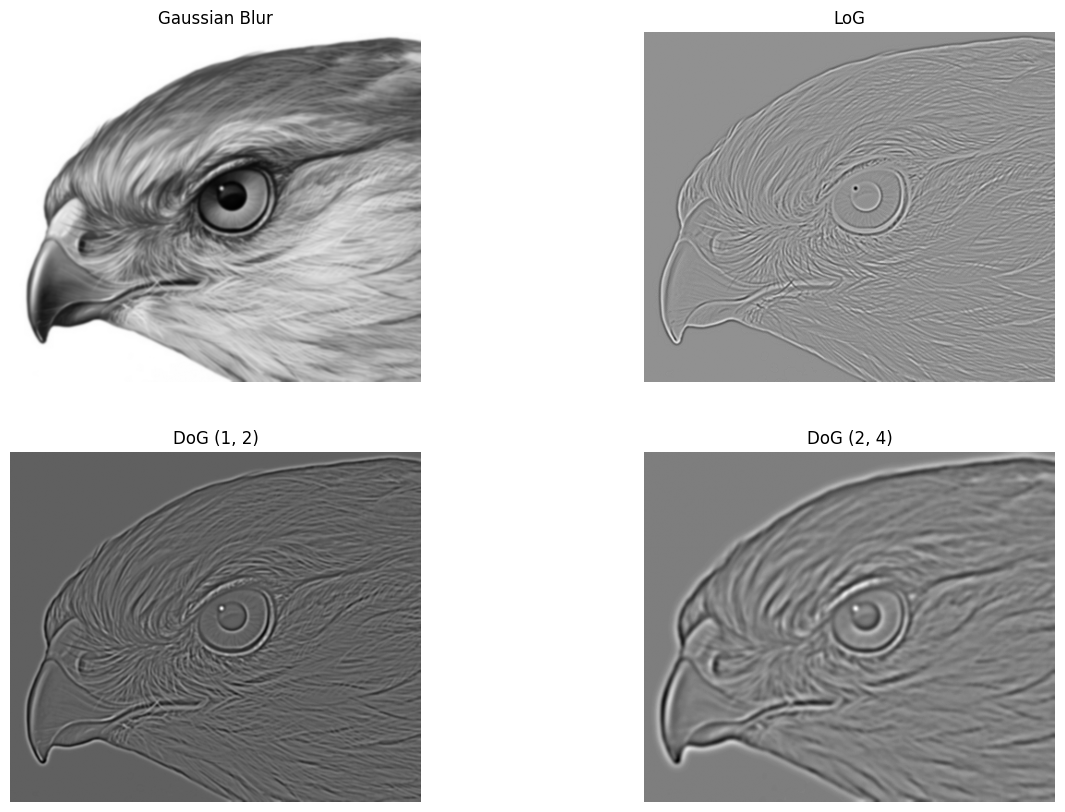

In [9]:
# TODO: blur, LoG, and DoG for the first sigma pair
blurred = cv2.GaussianBlur(img, (5, 5), 1)

# Laplacian of Gaussian
log = cv2.Laplacian(blurred, cv2.CV_64F)

# First DoG pair: sigma 1 and 2
gaussian_1 = cv2.GaussianBlur(img, (0, 0), 1)
gaussian_2 = cv2.GaussianBlur(img, (0, 0), 2)

dog_1 = gaussian_1.astype(np.float64) - gaussian_2.astype(np.float64)
# TODO: DoG for a second sigma pair
gaussian_3 = cv2.GaussianBlur(img, (0, 0), 2)
gaussian_4 = cv2.GaussianBlur(img, (0, 0), 4)

dog_2 = gaussian_3.astype(np.float64) - gaussian_4.astype(np.float64)

# TODO: show everything in one figure
plt.figure(figsize=(15, 10))

results = [
    (blurred, "Gaussian Blur"),
    (log, "LoG"),
    (dog_1, "DoG (1, 2)"),
    (dog_2, "DoG (2, 4)")
]

for i, (image, title) in enumerate(results):
    plt.subplot(2, 2, i + 1)
    plt.imshow(image, cmap='gray')
    plt.title(title)
    plt.axis('off')

plt.show()

**Question 6a:** Why do we blur before applying the Laplacian?

**Question 6b:** What changes in the DoG result when you increase the sigmas?

**Question 6c:** Which algorithm uses DoG for blob detection?

*Your answers:* 

## Part 7: Noise Experiment

Add noise to your image and see which filters survive.

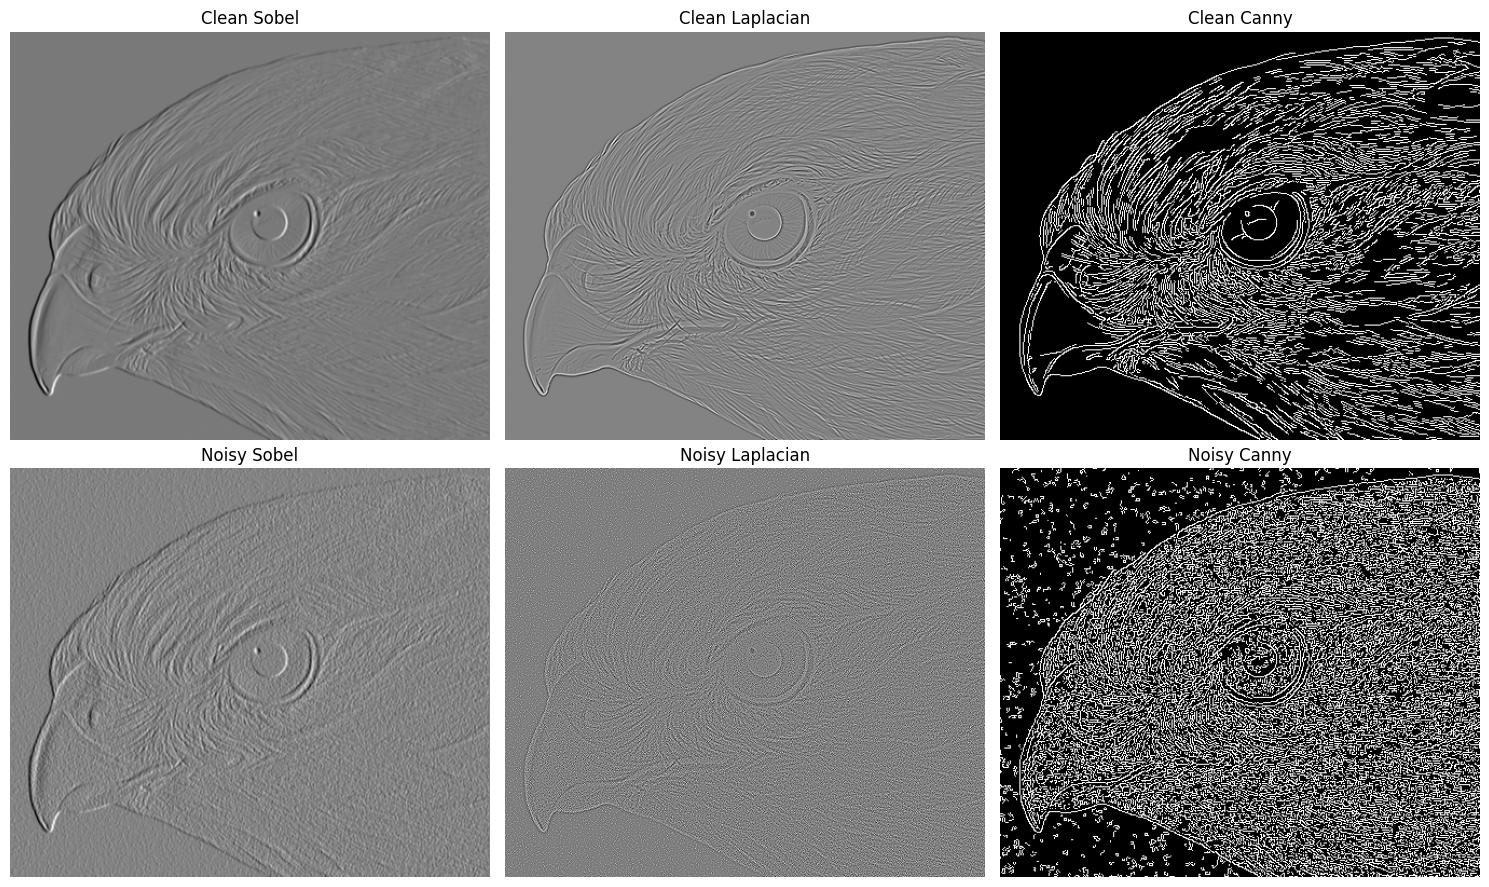

In [10]:
# TODO: create a noisy copy of your image
# Hint: noise = np.random.normal(0, 25, img.shape)
#       noisy = np.clip(img + noise, 0, 255).astype(np.uint8)
noise = np.random.normal(0, 25, img.shape)
noisy = np.clip(img.astype(np.float64) + noise, 0, 255).astype(np.uint8)

clean_sobel = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
clean_laplacian = cv2.Laplacian(img, cv2.CV_64F)
clean_canny = cv2.Canny(img, 100, 200)

# TODO: apply Sobel (3x3), Laplacian and Canny on the NOISY image
noisy_sobel = cv2.Sobel(noisy, cv2.CV_64F, 1, 0, ksize=3)
noisy_laplacian = cv2.Laplacian(noisy, cv2.CV_64F)
noisy_canny = cv2.Canny(noisy, 100, 200)


# TODO: show the 3 results next to the same 3 results from the clean image (2 rows x 3 columns)
plt.figure(figsize=(15, 9))

results = [
    (clean_sobel, "Clean Sobel"),
    (clean_laplacian, "Clean Laplacian"),
    (clean_canny, "Clean Canny"),
    (noisy_sobel, "Noisy Sobel"),
    (noisy_laplacian, "Noisy Laplacian"),
    (noisy_canny, "Noisy Canny")
]

for i, (image, title) in enumerate(results):
    plt.subplot(2, 3, i + 1)
    plt.imshow(image, cmap='gray')
    plt.title(title)
    plt.axis('off')

plt.tight_layout()
plt.show()

**Question 7:** Which filter was hurt the most by noise, and which handled it best? Explain why, using what you know about derivatives and smoothing.

*Your answer:* 

## Part 8: Final Comparison & Conclusion

Make one summary figure showing: Original, Sobel magnitude, Laplacian, Canny, LoG, DoG.

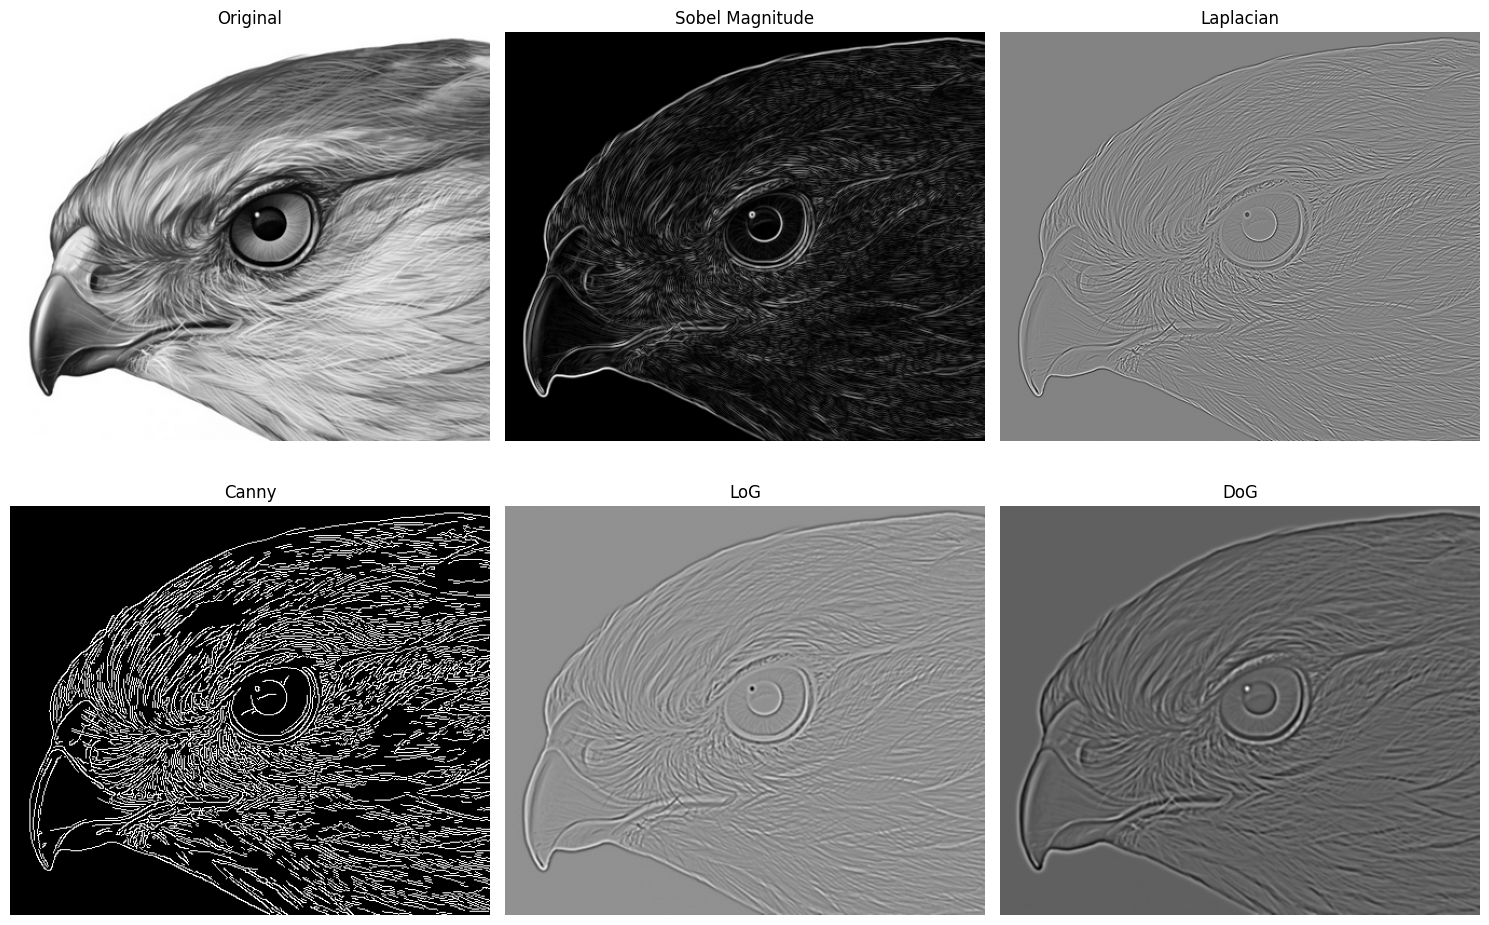

In [11]:
# TODO: 2x3 grid with all six results and titles
plt.figure(figsize=(15, 10))

results = [
    (img, "Original"),
    (magnitude, "Sobel Magnitude"),
    (laplacian, "Laplacian"),
    (canny_medium, "Canny"),
    (log, "LoG"),
    (dog_1, "DoG")
]

for i, (image, title) in enumerate(results):
    plt.subplot(2, 3, i + 1)
    plt.imshow(image, cmap='gray')
    plt.title(title)
    plt.axis('off')

plt.tight_layout()
plt.show()

**Final Question:** If you had to pick one method to detect the edges of objects in **your** image, which would you choose and why? Mention at least two trade-offs (noise, detail, thickness of edges, speed...).

*Your answer:* 
CANNY is the most well defioned and easy to use and it produces thin and well-defined edges while reducing noise through Gaussian smoothing.

---

### Bonus (optional)
- Try your code on a second image with very different content (a face, text, a landscape) and describe what changed.
- Combine Sobel X and Y into the magnitude **without** using `np.sqrt` (hint: `cv2.magnitude`) and check that you get the same result.